In [1]:
#Regression Analysis Example for Data Science

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [20]:
#libraries fron statsmodel
from statsmodels.formula.api import ols
import statsmodels.api as sm

In [21]:
#import the data
data=pd.read_csv('csv files/NYC_Building_Energy_and_Water_Data_Disclosure_for_Local_Law_84_2023_to_Present_(Data_for_Calendar_Year_2022-Present)_20261109.csv')
data.head(10)

,Property ID,Calendar Year,Borough,Postal Code,Largest Property Use Type,Largest Property Use Type - Gross Floor Area (ft²),Alert - Gross Floor Area is 0 ft2,Year Built,Number of Buildings,Site EUI (kBtu/ft²),ENERGY STAR Score,Total (Location-Based) GHG Emissions (Metric Tons CO2e),Direct GHG Emissions (Metric Tons CO2e),Direct GHG Emissions Intensity (kgCO2e/ft²),Indirect (Location-Based) GHG Emissions (Metric Tons CO2e),Indirect (Location-Based) GHG Emissions Intensity (kgCO2e/ft²),Natural Gas Use (kBtu),Natural Gas Use (therms)
0,53687992,2024,MANHATTAN,10017,Office,165378,Ok,2021,1,120.8,13,2062.89,682.03,3.32,1380.86,6.72,12840703.7,128407
1,54411292,2024,QUEENS,11373,Multifamily Housing,57285,Ok,2019,1,34.4,Not Available,231.21,47.69,0.66,183.53,2.53,897847,8978.5
2,66074492,2024,NaN,10128,Multifamily Housing,1541018,Ok,1974,3,51.5,51,8145.82,1247.41,0.77,6898.41,4.26,23485258,234852.6
3,2654832,2024,MANHATTAN,10021,Multifamily Housing,416253,Ok,1988,1,112,5,4402.85,1990.54,3.81,2412.31,4.62,37476380.3,374763.8
4,3111942,2024,QUEENS,11101,Multifamily Housing,72591,Ok,2010,1,44.3,82,358.06,77.57,0.88,280.49,3.19,1460425,14604.2
5,2660223,2024,MANHATTAN,10065,Multifamily Housing,228416,Ok,1957,1,57.1,78,980.52,458.24,1.99,522.29,2.27,8627336.2,86273.4
6,2729918,2024,QUEENS,11375,Multifamily Housing,129480,Ok,1964,1,70,70,668.47,375.11,2.74,293.36,2.15,6946685.5,69466.9
7,1461767,2024,MANHATTAN,10104,Office,1272198,Ok,1963,1,82.7,75,14369.23,41.84,0.02,14327.39,7.39,787729,7877.3
8,2806302,2024,MANHATTAN,10128,Multifamily Housing,79338,Ok,1954,1,69.3,Not Available,474.38,360.11,4.29,114.28,1.36,136104,1361
9,3205774,2024,BROOKLYN,11213,Multifamily Housing,41662,Ok,2002,1,58,Not Available,240.75,105.71,1.94,135.04,2.48,1990240.1,19902.4


In [22]:
data.shape

(39090, 18)

In [23]:
data.describe()

,Property ID,Calendar Year,Year Built,Number of Buildings
count,3.909000e+04,39090.0,39090.000000,39090.000000
mean,2.493053e+07,2024.0,1952.651804,1.414019
std,2.218178e+07,0.0,34.127999,5.670851
min,7.365000e+03,2024.0,1367.000000,0.000000
25%,6.236828e+06,2024.0,1927.000000,1.000000
50%,1.676782e+07,2024.0,1950.000000,1.000000
75%,5.054349e+07,2024.0,1972.000000,1.000000
max,6.613579e+07,2024.0,2088.000000,514.000000


In [24]:
print(data["Year Built"].sort_values().head(15))
print(data["Year Built"].sort_values().tail(15))

bad_year = (data["Year Built"] < 1800) | (data["Year Built"] > 2024)
print(bad_year.sum())
data.loc[bad_year, "Year Built"] = np.nan 
data["building_age"] = 2024 - data["Year Built"]

19501    1367
2440     1600
21300    1749
21299    1749
22038    1783
22046    1783
8548     1800
19687    1805
21283    1811
21284    1811
18142    1816
1843     1827
22323    1833
22332    1833
5971     1833
Name: Year Built, dtype: int64
28392    2024
36206    2024
29676    2024
28027    2024
28479    2024
34048    2024
27838    2024
38906    2025
36601    2025
31949    2025
24925    2025
29519    2025
36353    2025
23891    2028
16208    2088
Name: Year Built, dtype: int64
14


In [25]:
num_cols = ["Site EUI (kBtu/ft²)", "ENERGY STAR Score",
            "Largest Property Use Type - Gross Floor Area (ft²)",
            "Total (Location-Based) GHG Emissions (Metric Tons CO2e)"]
for c in num_cols:
    data[c] = pd.to_numeric(data[c], errors="coerce")
data[num_cols].describe()

,Site EUI (kBtu/ft²),ENERGY STAR Score,Largest Property Use Type - Gross Floor Area (ft²),Total (Location-Based) GHG Emissions (Metric Tons CO2e)
count,3.057700e+04,24338.000000,3.904600e+04,3.058700e+04
mean,5.137175e+03,62.654984,1.023322e+05,9.443253e+02
std,1.469262e+05,29.281757,2.520089e+05,1.604109e+04
min,-2.260000e+01,1.000000,1.000000e+00,-1.332100e+02
25%,4.940000e+01,42.000000,2.918775e+04,1.816900e+02
50%,6.950000e+01,69.000000,5.151800e+04,3.142000e+02
75%,9.100000e+01,87.000000,1.003190e+05,6.026800e+02
max,1.128538e+07,100.000000,1.908114e+07,1.930445e+06


In [26]:
eui = "Site EUI (kBtu/ft²)"
data = data[(data[eui] > 0) & (data[eui] < 1000)]

In [27]:
nob = "Number of Buildings"
data = data[(data[nob] >= 1) & (data[nob] <= 4)]

In [28]:
print(data["Borough"].isna().sum())

938


In [29]:
def zip_to_borough(z):
    try:
        z = int(str(z)[:5])
    except ValueError:
        return np.nan
    if 10001 <= z <= 10282:
        return "MANHATTAN"
    if 10301 <= z <= 10314:
        return "STATEN IS"
    if 10451 <= z <= 10475:
        return "BRONX"
    if 11201 <= z <= 11256:
        return "BROOKLYN"
    if 11004 <= z <= 11109 or 11351 <= z <= 11697:
        return "QUEENS"
    return np.nan

missing = data["Borough"].isna()
data.loc[missing, "Borough"] = data.loc[missing, "Postal Code"].apply(zip_to_borough)
print(data["Borough"].value_counts(dropna=False))

Borough
MANHATTAN    10681
BROOKLYN      7691
BRONX         5445
QUEENS        5159
STATEN IS      614
NaN             50
Name: count, dtype: int64


In [30]:
data = data.dropna(subset=["Borough"])

In [31]:
data.to_csv("ll84_2024_clean.csv", index=False)

In [32]:
eui = "Site EUI (kBtu/ft²)"
print((data[eui] <= 0).sum())
print(data.loc[data[eui] <= 0, ["Property ID", "Largest Property Use Type", eui]].head(10))

0
Empty DataFrame
Columns: [Property ID, Largest Property Use Type, Site EUI (kBtu/ft²)]
Index: []


In [33]:
gfa = "Largest Property Use Type - Gross Floor Area (ft²)"
data["log_eui"] = np.log(data[eui])
data["log_gfa"] = np.log(data[gfa])
# building_age was created earlier

In [34]:
data = data[(data[eui] >= 10) & (data[eui] < 1000)]

                     log_eui  building_age  log_gfa  Number of Buildings  \
log_eui                 1.00          0.09    -0.07                 0.02   
building_age            0.09          1.00    -0.14                -0.01   
log_gfa                -0.07         -0.14     1.00                 0.16   
Number of Buildings     0.02         -0.01     0.16                 1.00   
ENERGY STAR Score      -0.69         -0.00     0.07                -0.01   

                     ENERGY STAR Score  
log_eui                          -0.69  
building_age                     -0.00  
log_gfa                           0.07  
Number of Buildings              -0.01  
ENERGY STAR Score                 1.00  
                     log_eui  building_age  log_gfa  Number of Buildings  \
log_eui                 1.00          0.11    -0.10                 0.01   
building_age            0.11          1.00    -0.18                -0.02   
log_gfa                -0.10         -0.18     1.00                 0

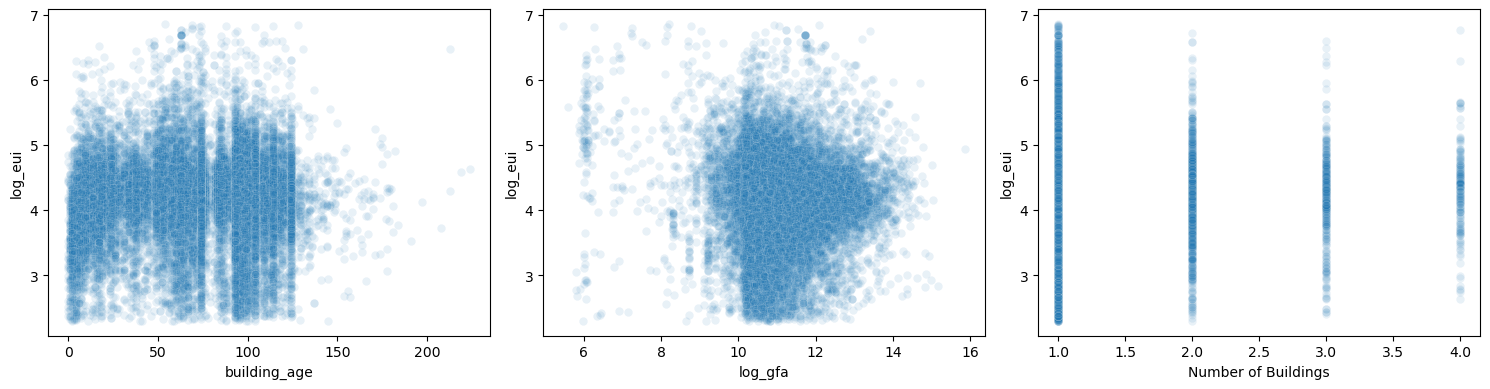

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=data, x="building_age", y="log_eui", alpha=0.1, ax=axes[0])
sns.scatterplot(data=data, x="log_gfa", y="log_eui", alpha=0.1, ax=axes[1])
sns.scatterplot(data=data, x="Number of Buildings", y="log_eui", alpha=0.1, ax=axes[2])
plt.tight_layout()

cols = ["log_eui", "building_age", "log_gfa", "Number of Buildings", "ENERGY STAR Score"]
print(data[cols].corr(method="pearson").round(2))
print(data[cols].corr(method="spearman").round(2))

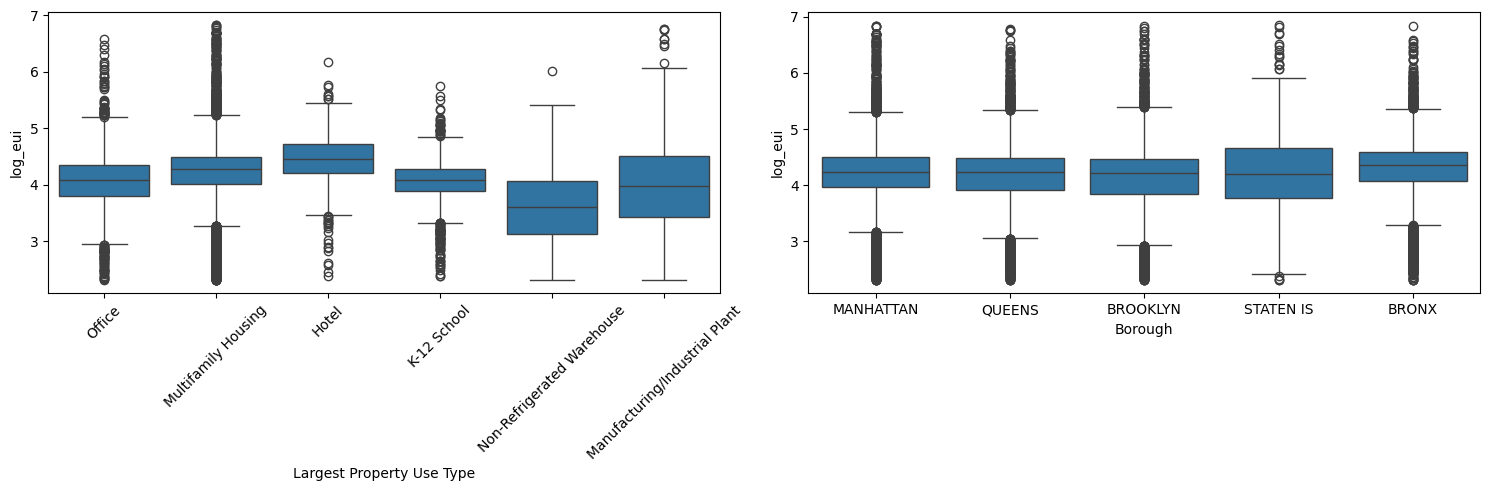

In [42]:
top_types = data["Largest Property Use Type"].value_counts().head(6).index
sub = data[data["Largest Property Use Type"].isin(top_types)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=sub, x="Largest Property Use Type", y="log_eui", ax=axes[0])
axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=data, x="Borough", y="log_eui", ax=axes[1])
plt.tight_layout()

bins = [0, 45, 85, 120, 300]
labels = ["2005+", "1940-1979", "1905-1939", "pre-1905"]
data["age_band"] = pd.cut(data["building_age"], bins=bins, labels=labels, right=False)

data["ptype"] = data["Largest Property Use Type"].where(
    data["Largest Property Use Type"].isin(top_types), "Other")

In [43]:
import statsmodels.formula.api as smf

ghg_d = "Direct GHG Emissions Intensity (kgCO2e/ft²)"
ghg_i = "Indirect (Location-Based) GHG Emissions Intensity (kgCO2e/ft²)"
gas = "Natural Gas Use (kBtu)"

h = data[data["Largest Property Use Type"] == "Hotel"].copy()
for c in [ghg_d, ghg_i, gas]:
    h[c] = pd.to_numeric(h[c], errors="coerce")

h["ghg_int"] = h[ghg_d] + h[ghg_i]            # total kgCO2e/ft²
h["site_kbtu"] = h[eui] * h[gfa]                # approximate total site energy
h["gas_share"] = (h[gas] / h["site_kbtu"]).clip(0, 1)
print(len(h))
print(h["age_band"].value_counts())
print(h[["building_age", eui, "ghg_int", "ENERGY STAR Score", "gas_share"]].describe())

668
age_band
2005+        438
1905-1939    133
1940-1979     51
pre-1905      46
Name: count, dtype: int64
       building_age  Site EUI (kBtu/ft²)     ghg_int  ENERGY STAR Score  \
count    668.000000           668.000000  654.000000         631.000000   
mean      44.895210            94.033084    8.079924          48.532488   
std       42.667268            45.098320    3.412646          28.627634   
min        0.000000            10.900000    1.080000           1.000000   
25%       11.000000            67.275000    5.920000          24.000000   
50%       22.000000            86.550000    7.355000          49.000000   
75%       94.000000           111.725000    9.487500          71.000000   
max      219.000000           481.100000   31.740000         100.000000   

        gas_share  
count  653.000000  
mean     0.422866  
std      0.228340  
min      0.000000  
25%      0.293152  
50%      0.438011  
75%      0.557488  
max      1.000000  


                   building_age  log_eui  ghg_int  ENERGY STAR Score  \
building_age               1.00     0.13     0.08               0.00   
log_eui                    0.13     1.00     0.95              -0.73   
ghg_int                    0.08     0.95     1.00              -0.77   
ENERGY STAR Score          0.00    -0.73    -0.77               1.00   
gas_share                  0.01     0.31     0.10              -0.07   

                   gas_share  
building_age            0.01  
log_eui                 0.31  
ghg_int                 0.10  
ENERGY STAR Score      -0.07  
gas_share               1.00  


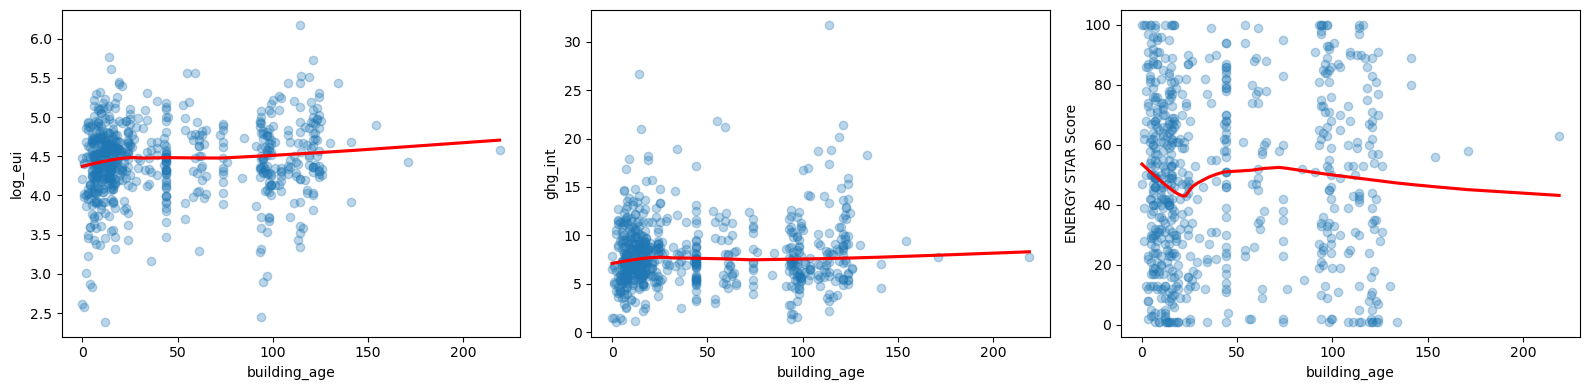

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, y in zip(axes, ["log_eui", "ghg_int", "ENERGY STAR Score"]):
    sns.regplot(data=h, x="building_age", y=y, lowess=True,
                scatter_kws={"alpha": 0.3}, line_kws={"color": "red"}, ax=ax)
plt.tight_layout()

print(h[["building_age", "log_eui", "ghg_int", "ENERGY STAR Score", "gas_share"]]
      .corr(method="spearman").round(2))

In [45]:
f = "~ C(age_band) + log_gfa + gas_share + C(Borough, Treatment('MANHATTAN'))"
m_eui = smf.ols("log_eui " + f, data=h).fit(cov_type="HC3")
m_ghg = smf.ols("ghg_int " + f, data=h).fit(cov_type="HC3")
print(len(h), h["age_band"].value_counts().to_dict())
print(m_eui.summary())
print(m_ghg.summary())

668 {'2005+': 438, '1905-1939': 133, '1940-1979': 51, 'pre-1905': 46}
                            OLS Regression Results                            
Dep. Variable:                log_eui   R-squared:                       0.186
Model:                            OLS   Adj. R-squared:                  0.174
Method:                 Least Squares   F-statistic:                     15.08
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           2.20e-22
Time:                        03:38:57   Log-Likelihood:                -361.12
No. Observations:                 653   AIC:                             742.2
Df Residuals:                     643   BIC:                             787.0
Df Model:                           9                                         
Covariance Type:                  HC3                                         
                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------